# Lecture 9: Machine Learning & Deep Learning

- Lecture 8 was about **inference**: estimating relationships and testing whether they're real.

- This lecture is about **prediction**: building models that forecast well on data they haven't seen.

- In inference we care about coefficients and standard errors; in prediction we care about out-of-sample accuracy.

- A model can be good for one goal and poor for the other, so we evaluate the two separately.

## What We'll Cover

- **Ch 19 (scikit-learn):** the machine-learning workflow, including train/test splits, regularization, cross-validation, pipelines, and tree-based models.
- **Ch 20 (PyTorch):** a first, exposure-level look at deep learning, covering tensors, autograd, and the training loop.

- The running example is forecasting the S&P 500.
  - Returns are hard to predict because markets are close to efficient.
  - Volatility is much easier to predict because it clusters. This connects to the GARCH model from Lecture 8.

## Leakage and Out-of-Sample Evaluation

- It is easy to appear to predict markets by accidentally letting future information leak into the features, or by reporting in-sample fit.

- We follow two rules throughout:
  1. **No look-ahead:** every feature uses only past data.
  2. **Out-of-sample evaluation:** we judge models on a held-out test period, in chronological order.

## Setup: Installing and Importing Libraries

- `scikit-learn`, `numpy`, `pandas`, and `torch` are pre-installed in Colab.
- We install `yfinance` (to download prices) and `arch` (for the GARCH comparison).

In [ ]:
!pip install -q yfinance arch

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

## Loading S&P 500 Data

- We download daily S&P 500 prices. The loader below tries `yfinance` first and falls back to Stooq and then FRED, so the notebook still works if one source is down.

In [ ]:
import warnings

def load_sp500(start='2010-01-01', end='2024-12-31'):
    """Load daily S&P 500 closing prices. Tries yfinance, then Stooq, then FRED."""
    # 1) yfinance — the standard tool for market data
    try:
        import yfinance as yf
        data = yf.download('^GSPC', start=start, end=end,
                           progress=False, auto_adjust=True)
        if len(data) > 0:
            close = data['Close']
            if isinstance(close, pd.DataFrame):   # newer yfinance returns MultiIndex cols
                close = close.iloc[:, 0]
            return close.rename('SP500').dropna()
    except Exception as e:
        print(f"yfinance failed ({type(e).__name__}); trying Stooq.")
    # 2) Stooq via pandas-datareader (reliable, no API key)
    try:
        import pandas_datareader.data as web
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', FutureWarning)
            data = web.DataReader('^SPX', 'stooq', start=start, end=end)
        return data['Close'].sort_index().rename('SP500').dropna()
    except Exception as e:
        print(f"Stooq failed ({type(e).__name__}); trying FRED.")
    # 3) FRED (closing price only, ~10 years of history)
    import pandas_datareader.data as web
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', FutureWarning)
        data = web.DataReader('SP500', 'fred', start=start, end=end)
    return data['SP500'].dropna().rename('SP500')

In [ ]:
sp500 = load_sp500()
sp500.tail()

,SP500
Date,
2024-12-23,5974.069824
2024-12-24,6040.040039
2024-12-26,6037.589844
2024-12-27,5970.839844
2024-12-30,5906.939941


In [ ]:
print(f"Observations: {len(sp500)}")
print(f"Date range: {sp500.index.min():%Y-%m-%d} to {sp500.index.max():%Y-%m-%d}")

Observations: 3773
Date range: 2010-01-04 to 2024-12-30


### Visualizing the Price Series

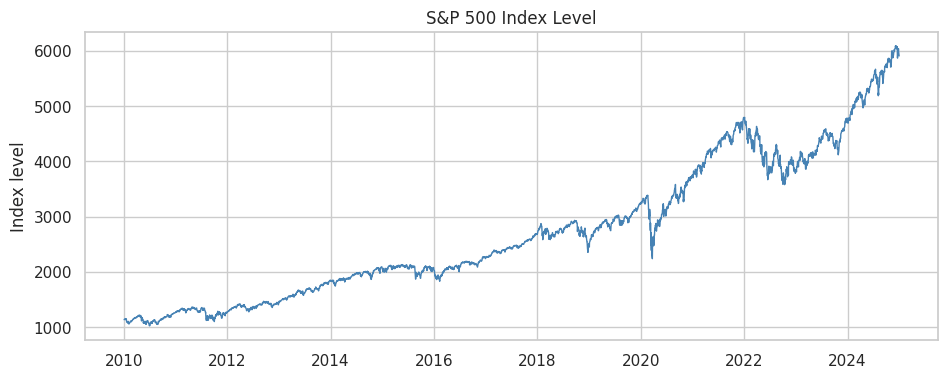

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(sp500.index, sp500, color='steelblue', linewidth=1)
ax.set_title('S&P 500 Index Level')
ax.set_ylabel('Index level')
plt.show()

### From Prices to Returns

- We model returns rather than price levels. A price series is non-stationary (it trends and wanders), and predicting tomorrow's price is nearly trivial because it is close to today's.

- Daily returns are roughly stationary and are the quantity we care about.

In [ ]:
returns = sp500.pct_change().dropna()
returns.head()

,SP500
Date,
2010-01-05,0.003116
2010-01-06,0.000546
2010-01-07,0.004001
2010-01-08,0.002882
2010-01-11,0.001747


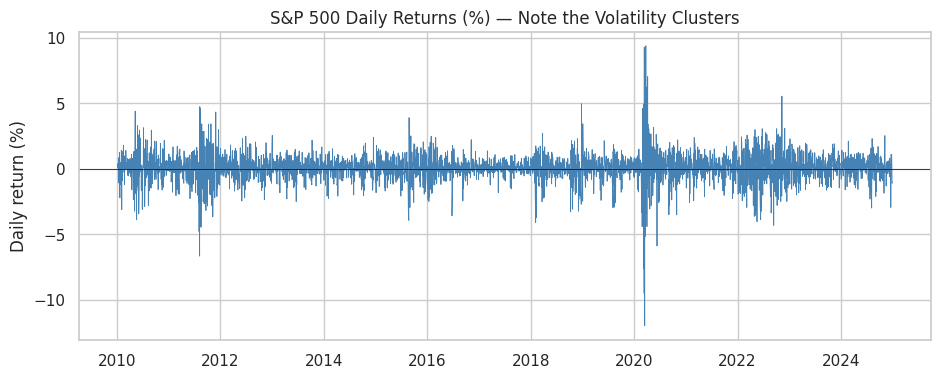

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(returns.index, returns * 100, color='steelblue', linewidth=0.6)
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('S&P 500 Daily Returns (%) — Note the Volatility Clusters')
ax.set_ylabel('Daily return (%)')
plt.show()

- The return series shows **volatility clustering**: calm stretches and turbulent stretches group together. We use this later to forecast volatility.

# Ch 19: Machine Learning with scikit-learn

- `scikit-learn` is the standard Python library for machine learning.

- Every model follows the same **estimator API**:
  - `model.fit(X, y)` learns from training data.
  - `model.predict(X)` makes predictions.
  - `model.score(X, y)` evaluates performance.

- This consistency means swapping a linear model for a random forest is a one-line change.

## The Machine-Learning Workflow

- The steps are almost always the same:
  1. **Build features** (`X`) and a target (`y`).
  2. **Split** into training and test sets.
  3. **Fit** a model on the training set.
  4. **Evaluate** on the held-out test set.
  5. **Tune** with cross-validation, then re-evaluate.

## Feature Engineering

- Models learn from **features**. From a single return series we can build many predictive inputs.

- Every feature must use only past information. We `shift` each series so that today's feature never uses today's or tomorrow's return.

In [ ]:
data = pd.DataFrame({'ret': returns})

# Lagged returns: yesterday's, 2 days ago, etc.
for k in [1, 2, 3, 5]:
    data[f'ret_lag{k}'] = data['ret'].shift(k)

data.head()

,ret,ret_lag1,ret_lag2,ret_lag3,ret_lag5
Date,,,,,
2010-01-05,0.003116,NaN,NaN,NaN,NaN
2010-01-06,0.000546,0.003116,NaN,NaN,NaN
2010-01-07,0.004001,0.000546,0.003116,NaN,NaN
2010-01-08,0.002882,0.004001,0.000546,0.003116,NaN
2010-01-11,0.001747,0.002882,0.004001,0.000546,NaN


### Moving Averages and Momentum

- Short- and medium-term average returns, plus 21-day momentum (about one trading month).

In [ ]:
data['ma5'] = data['ret'].rolling(5).mean().shift(1)
data['ma21'] = data['ret'].rolling(21).mean().shift(1)
data['mom21'] = data['ret'].rolling(21).sum().shift(1)
data[['ma5', 'ma21', 'mom21']].head(8)

,ma5,ma21,mom21
Date,,,
2010-01-05,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN
2010-01-12,0.002458,NaN,NaN
2010-01-13,-0.000041,NaN,NaN
2010-01-14,0.001515,NaN,NaN


### Volatility Features (HAR-style)

- Past **realized volatility** at several horizons (5, 21, and 63 days). These are the standard predictors of future volatility.

- We annualize and convert to percent (multiply by sqrt(252) and by 100) so the numbers are easier to read.

In [ ]:
ANN = np.sqrt(252) * 100   # annualize daily vol to percent

data['vol5'] = data['ret'].rolling(5).std().shift(1) * ANN
data['vol21'] = data['ret'].rolling(21).std().shift(1) * ANN
data['vol63'] = data['ret'].rolling(63).std().shift(1) * ANN
data[['vol5', 'vol21', 'vol63']].head(8)

,vol5,vol21,vol63
Date,,,
2010-01-05,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN
2010-01-12,2.123419,NaN,NaN
2010-01-13,8.536166,NaN,NaN
2010-01-14,10.446403,NaN,NaN


### Defining the Targets

- **Return target:** tomorrow's return (`shift(-1)`).
- **Direction target:** whether tomorrow is up (1) or down (0).
- **Volatility target:** realized volatility over the *next* 21 days, annualized.

In [ ]:
data['target_ret'] = data['ret'].shift(-1)
data['target_dir'] = (data['target_ret'] > 0).astype(int)
data['target_vol'] = data['ret'].rolling(21).std().shift(-21) * ANN

# Drop rows with missing values created by shifting/rolling
data = data.dropna()
print(f"Final dataset shape: {data.shape}")
data.head()

Final dataset shape: (3688, 14)


,ret,ret_lag1,ret_lag2,ret_lag3,ret_lag5,ma5,ma21,mom21,vol5,vol21,vol63,target_ret,target_dir,target_vol
Date,,,,,,,,,,,,,,
2010-04-07,-0.005877,0.001684,0.007928,0.007414,0.000043,0.002759,0.002086,0.043812,7.666855,6.580531,13.997103,0.003374,1,20.611468
2010-04-08,0.003374,-0.005877,0.001684,0.007928,-0.003273,0.001575,0.001815,0.038111,9.833674,7.103050,14.052344,0.006684,1,20.992509
2010-04-09,0.006684,0.003374,-0.005877,0.001684,0.007414,0.002905,0.001894,0.039773,8.852387,7.123335,14.062729,0.001767,1,26.438090
2010-04-12,0.001767,0.006684,0.003374,-0.005877,0.007928,0.002759,0.001997,0.041932,8.630552,7.261742,14.098417,0.000685,1,26.423899
2010-04-13,0.000685,0.001767,0.006684,0.003374,0.001684,0.001526,0.001888,0.039657,7.313627,7.223691,14.093344,0.011150,1,26.942706


In [ ]:
# The list of feature columns we'll feed to models
feature_cols = ['ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_lag5',
                'ma5', 'ma21', 'mom21', 'vol5', 'vol21', 'vol63']
print(feature_cols)

['ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_lag5', 'ma5', 'ma21', 'mom21', 'vol5', 'vol21', 'vol63']


## Train/Test Split for Time Series

- For time series, the train/test split must be **chronological**, never random.

- A random split would let the model train on future days and predict past days. This is called **look-ahead leakage**; it makes results look good, but they could not have been achieved in real time.

- We train on the first 80% of the timeline and test on the last 20%.

In [ ]:
split = int(len(data) * 0.8)
train = data.iloc[:split]
test = data.iloc[split:]

print(f"Train: {train.index.min():%Y-%m} to {train.index.max():%Y-%m}  ({len(train)} days)")
print(f"Test:  {test.index.min():%Y-%m} to {test.index.max():%Y-%m}  ({len(test)} days)")

Train: 2010-04 to 2021-12  (2950 days)
Test:  2021-12 to 2024-11  (738 days)


**Note:** we do not use scikit-learn's `train_test_split` here.

- `train_test_split` shuffles by default. That is fine for cross-sectional data but wrong for time series.
- We slice by position instead.

## Predicting Returns

- We first try to predict tomorrow's return with a linear model, using the estimator API.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X_train, y_train = train[feature_cols], train['target_ret']
X_test, y_test = test[feature_cols], test['target_ret']

lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
train_r2 = lr.score(X_train, y_train)
test_r2 = r2_score(y_test, lr.predict(X_test))
print(f"In-sample  R2: {train_r2:.4f}")
print(f"Out-of-sample R2: {test_r2:.4f}")

In-sample  R2: 0.0305
Out-of-sample R2: -0.0297


### Results

- The out-of-sample R-squared is essentially zero (often slightly negative).

- This is expected under the **efficient-market hypothesis**. If daily returns were easily predictable from past returns, traders would already have arbitraged the pattern away.

- A negative test R-squared means the model does worse than predicting the mean. Be skeptical of anyone claiming to predict daily returns with high accuracy.

## Regularization: Ridge and Lasso

- **Regularization** shrinks coefficients toward zero to reduce overfitting. This connects directly to OLS from Lecture 8.

- **Ridge** (L2) shrinks all coefficients smoothly.
- **Lasso** (L1) can set some coefficients exactly to zero, so it also performs variable selection.

In [ ]:
from sklearn.linear_model import Ridge, Lasso

ridge = Ridge(alpha=1.0).fit(X_train, y_train)
lasso = Lasso(alpha=0.001).fit(X_train, y_train)

coefs = pd.DataFrame({
    'OLS': lr.coef_,
    'Ridge': ridge.coef_,
    'Lasso': lasso.coef_,
}, index=feature_cols)
coefs.round(5)

,OLS,Ridge,Lasso
ret_lag1,0.12904,0.02648,0.00000
ret_lag2,-0.00400,-0.00879,-0.00000
ret_lag3,-0.03717,-0.01388,-0.00000
ret_lag5,-0.07652,-0.02563,-0.00000
ma5,-0.14649,-0.00484,-0.00000
ma21,-0.00076,-0.00059,-0.00000
mom21,-0.01601,-0.01235,-0.00000
vol5,-0.00014,-0.00008,-0.00000
vol21,0.00006,0.00003,0.00000
vol63,0.00011,0.00009,0.00004


- Lasso sets many coefficients to zero. When predicting returns it typically keeps almost no features, which matches the near-zero out-of-sample R-squared of the linear model.

### Choosing `alpha` with Cross-Validation

- `LassoCV` automatically selects the regularization strength using cross-validation.

In [ ]:
from sklearn.linear_model import LassoCV
from sklearn.model_selection import TimeSeriesSplit

lasso_cv = LassoCV(cv=TimeSeriesSplit(5), max_iter=50000)
lasso_cv.fit(X_train, y_train)
print(f"Selected alpha: {lasso_cv.alpha_:.2e}")
print(f"Non-zero coefficients: {np.sum(lasso_cv.coef_ != 0)} of {len(feature_cols)}")

Selected alpha: 2.89e-03
Non-zero coefficients: 1 of 10


## Cross-Validation for Time Series

- Ordinary k-fold CV ignores the time order of the data, which is again wrong for time series.

- `TimeSeriesSplit` creates folds that always train on the past and validate on the future.

In [ ]:
from sklearn.model_selection import cross_val_score

tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(LinearRegression(), X_train, y_train,
                         cv=tscv, scoring='r2')
print("Validation R2 per fold:", np.round(scores, 4))
print(f"Mean: {scores.mean():.4f}")

Validation R2 per fold: [-0.0505 -0.0199 -0.054  -0.0074 -0.0163]
Mean: -0.0296


- Each fold's validation set comes after its training set in time. The validation R-squared is near zero in every fold, as it was on the test set.

## Preprocessing Pipelines

- Many models need scaled features. The scaling must be learned on the **training set only**; otherwise test information leaks in.

- A `Pipeline` bundles preprocessing and the model so the scaler is fit on each training fold automatically.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
pipe.fit(X_train, y_train)
print(f"Pipeline test R2: {pipe.score(X_test, y_test):.4f}")

Pipeline test R2: -0.0296


- The `Pipeline` applies `StandardScaler` and then `Ridge` as one object, so there is no manual scaling step and the scaler is fit only on the training data.

## Tree-Based Models

- **Decision trees** split the feature space into regions. They capture nonlinearities and interactions automatically.

- **Random forests** average many trees fit on bootstrapped samples. They are usually more accurate and more stable than a single tree.

- **Gradient boosting** builds trees sequentially, with each new tree correcting the errors of the trees before it. It is often the best performer on tabular data.

In [ ]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
print(f"Random Forest (returns) test R2: {rf.score(X_test, y_test):.4f}")

Random Forest (returns) test R2: -0.0579


- The random forest does not predict returns out of sample either. A more flexible model cannot find signal that is not in the data.

## Classification: Predicting Direction

- Next we check whether the sign of tomorrow's return is easier to predict than its magnitude.

- This is a **classification** problem (up vs down). We measure accuracy, the fraction of days classified correctly.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

yd_train, yd_test = train['target_dir'], test['target_dir']

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_train, yd_train)

acc = accuracy_score(yd_test, clf.predict(X_test))
print(f"Direction accuracy: {acc:.4f}")
print(f"Baseline (always predict 'up'): {yd_test.mean():.4f}")

Direction accuracy: 0.5149
Baseline (always predict 'up'): 0.5176


### Reading a Confusion Matrix

- The confusion matrix shows correct vs incorrect calls for each class.

In [ ]:
cm = confusion_matrix(yd_test, clf.predict(X_test))
cm_df = pd.DataFrame(cm,
                     index=['Actual Down', 'Actual Up'],
                     columns=['Pred Down', 'Pred Up'])
cm_df

,Pred Down,Pred Up
Actual Down,8,348
Actual Up,10,372


- Accuracy is close to the base rate (always predicting up), so direction prediction is barely better than a coin flip. As with returns, this is consistent with market efficiency.

## Predicting Volatility

- Volatility clusters, so next month's volatility is predictable from the recent past.

- We keep the same features and workflow and change the target to `target_vol`.

- The standard model for forecasting realized volatility, the **HAR** model, is a linear regression of future volatility on past volatility at several horizons. We start there.

In [ ]:
yv_train, yv_test = train['target_vol'], test['target_vol']

# A regularized linear model (HAR-style), in a pipeline with scaling
vol_lin = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
vol_lin.fit(X_train, yv_train)

vol_r2 = vol_lin.score(X_test, yv_test)
print(f"Volatility test R2 (linear): {vol_r2:.4f}")
print("(Compare to the near-zero R2 for returns!)")

Volatility test R2 (linear): 0.4452
(Compare to the near-zero R2 for returns!)


### Comparison with Returns

- The test R-squared is much higher than for returns.

- More generally, financial returns are hard to forecast, while volatility is often forecastable.

### Linear Model Coefficients

- In a linear model with standardized features, the coefficients show which features drive the forecast. We expect the past-volatility features to dominate.

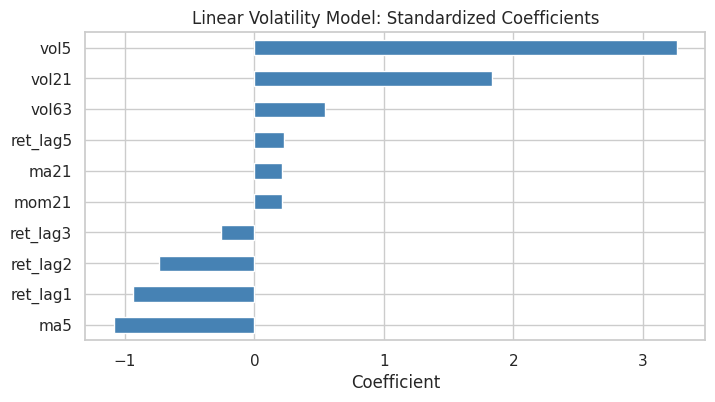

In [ ]:
# Pull coefficients out of the fitted pipeline
ridge_step = vol_lin.named_steps['ridge']
vol_coefs = pd.Series(ridge_step.coef_, index=feature_cols).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
vol_coefs.plot.barh(ax=ax, color='steelblue')
ax.set_title('Linear Volatility Model: Standardized Coefficients')
ax.set_xlabel('Coefficient')
plt.show()

### Random Forest for Volatility

- A random forest can also predict volatility, and it reports **feature importances**.

- Trees **cannot extrapolate**. Their predictions stay within the range of target values seen in training, so if a future crisis brings higher volatility than anything in the training data, a tree will systematically under-predict it. A linear model can extrapolate.

Volatility test R2 (random forest): 0.1972


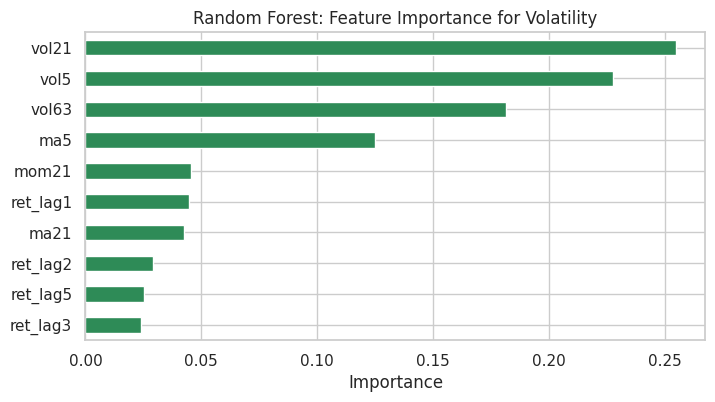

In [ ]:
rf_vol = RandomForestRegressor(n_estimators=200, random_state=42)
rf_vol.fit(X_train, yv_train)
print(f"Volatility test R2 (random forest): {rf_vol.score(X_test, yv_test):.4f}")

importances = pd.Series(rf_vol.feature_importances_, index=feature_cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
importances.plot.barh(ax=ax, color='seagreen')
ax.set_title('Random Forest: Feature Importance for Volatility')
ax.set_xlabel('Importance')
plt.show()

### Visualizing the Volatility Forecast

- Plot predicted vs actual volatility on the test set for the linear model.

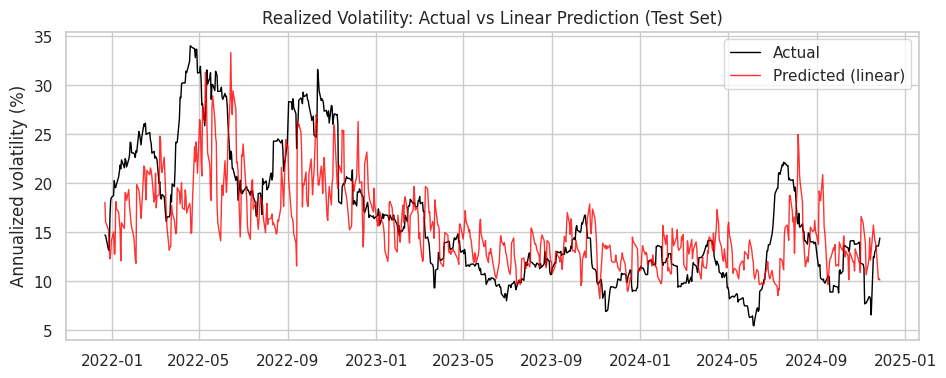

In [ ]:
pred_vol = vol_lin.predict(X_test)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(yv_test.index, yv_test, label='Actual', color='black', linewidth=1)
ax.plot(yv_test.index, pred_vol, label='Predicted (linear)', color='red', linewidth=1, alpha=0.8)
ax.set_title('Realized Volatility: Actual vs Linear Prediction (Test Set)')
ax.set_ylabel('Annualized volatility (%)')
ax.legend()
plt.show()

## Connection to GARCH

- In Lecture 8 we modeled volatility structurally with GARCH. Here we predicted it with a data-driven ML model.

- We now fit a GARCH(1,1) to the S&P 500 returns and compare its conditional volatility with the market's actual ups and downs.

In [ ]:
from arch import arch_model

# arch expects returns in percent; daily returns are tiny, so scale by 100
am = arch_model(returns * 100, mean='Constant', vol='GARCH', p=1, q=1)
garch_res = am.fit(disp='off')

# Annualize the daily conditional volatility to compare with our ML target
garch_vol = garch_res.conditional_volatility * np.sqrt(252)
garch_vol.tail()

,cond_vol
Date,
2024-12-23,18.959831
2024-12-24,17.759772
2024-12-26,17.494834
2024-12-27,15.992890
2024-12-30,16.534878


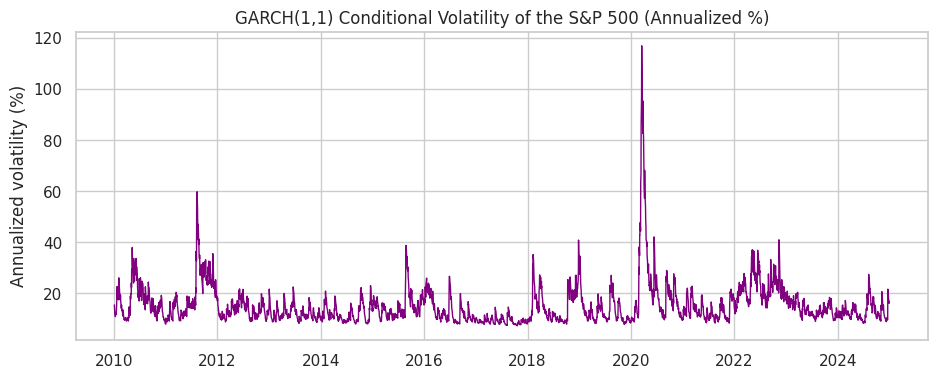

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(garch_vol.index, garch_vol, color='purple', linewidth=1)
ax.set_title('GARCH(1,1) Conditional Volatility of the S&P 500 (Annualized %)')
ax.set_ylabel('Annualized volatility (%)')
plt.show()

- GARCH is a parametric model with three parameters and strong structure. The random forest is flexible and makes few assumptions.

- Both capture the fact that volatility is persistent and forecastable. GARCH reflects the inference approach and the random forest reflects the prediction approach.

## In-Class Exercise

**19-1. Add a Feature:**
- Add a new feature to `data` called `ret_lag10` (the return 10 days ago).
- Use `.shift(10)` and confirm it appears as a column.

**19-2. Random Forest for Returns:**
- Fit a `RandomForestRegressor` to predict `target_ret` (tomorrow's return) using `feature_cols`.
- Report the out-of-sample R-squared. Is it meaningfully above zero?

**19-3. Regularization Path:**
- Fit `Lasso` to predict `target_ret` with three different `alpha` values: 0.0001, 0.001, and 0.01.
- For each, print how many coefficients are non-zero. What happens as `alpha` grows?

**19-4. Gradient Boosting for Volatility:**
- Fit a `GradientBoostingRegressor` to predict `target_vol`.
- Compare its test R-squared to the random forest's. Which does better?

**19-5. Feature Importance:**
- From your volatility model in 19-4 (or the random forest), print the three most important features.
- Do the volatility features (`vol5`, `vol21`, `vol63`) dominate, as expected?

# Ch 20: Deep Learning with PyTorch

- **PyTorch** is one of the two dominant deep-learning frameworks (alongside TensorFlow).

- This chapter gives an exposure-level introduction to tensors, automatic differentiation, and the training loop.

- For tabular econ/finance problems, gradient boosting (Ch 19) usually performs better than deep learning. Deep learning is most useful for images, text, and sequences, and for very large datasets.

In [ ]:
import torch
import torch.nn as nn

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.11.0+cpu


## Tensors

- A **tensor** is PyTorch's core data structure. It is essentially a NumPy array that can run on a GPU and track gradients.

- If you know NumPy (Lecture 6), you already know most of the tensor API.

In [ ]:
# Create tensors much like NumPy arrays
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([4.0, 5.0, 6.0])
print(a + b)
print(a * b)
print(a.mean())

tensor([5., 7., 9.])
tensor([ 4., 10., 18.])
tensor(2.)


In [ ]:
# 2D tensor and its shape
M = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print(M)
print("Shape:", M.shape)

tensor([[1., 2.],
        [3., 4.]])
Shape: torch.Size([2, 2])


### Converting Between NumPy and PyTorch

- `torch.from_numpy()` converts a NumPy array to a tensor, and `.numpy()` converts a tensor back to a NumPy array.

In [ ]:
arr = np.array([1.0, 2.0, 3.0])
t = torch.from_numpy(arr)      # NumPy -> tensor
back = t.numpy()               # tensor -> NumPy
print("tensor:", t)
print("back to numpy:", back)

tensor: tensor([1., 2., 3.], dtype=torch.float64)
back to numpy: [1. 2. 3.]


## Autograd: Automatic Differentiation

- Neural networks are trained by **gradient descent**, and the gradients can be tedious to derive by hand.

- PyTorch's **autograd** computes them automatically. Set `requires_grad=True`, do a calculation, then call `.backward()`.

In [ ]:
# Compute the derivative of f(x) = x^2 + 2x at x = 3
x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 2*x
y.backward()          # compute dy/dx
print(f"dy/dx at x=3: {x.grad.item()}")   # analytically 2x + 2 = 8

dy/dx at x=3: 8.0


- Network training relies on autograd: PyTorch tracks every operation and can differentiate the whole chain back to the parameters.

## Building a Neural Network

- A neural network is a stack of linear layers with **nonlinear activations** in between.

- In PyTorch you define one as a class that subclasses `nn.Module` (classes were covered in Lecture 5). You implement `__init__` (define the layers) and `forward` (define the computation).

In [ ]:
class VolNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 16),   # input -> 16 hidden units
            nn.ReLU(),                   # nonlinearity
            nn.Linear(16, 8),            # 16 -> 8
            nn.ReLU(),
            nn.Linear(8, 1),             # 8 -> single output
        )

    def forward(self, x):
        return self.net(x)

model = VolNet(n_features=len(feature_cols))
print(model)

VolNet(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


- `nn.Sequential` chains layers; `nn.Linear(a, b)` is a fully-connected layer; `nn.ReLU` is the activation. The output layer has one unit because we predict a single number (volatility).

## Preparing the Data as Tensors

- We reuse the volatility prediction task from Ch 19, since volatility (unlike returns) was predictable out of sample.

- Neural nets train best when both inputs and outputs are standardized. We compute the means and standard deviations on the **training set only** and use them to scale the test features as well.

In [ ]:
# Standardize features and target using TRAINING statistics only
X_tr = train[feature_cols].values.astype('float32')
X_te = test[feature_cols].values.astype('float32')
y_tr = train['target_vol'].values.astype('float32').reshape(-1, 1)
y_te = test['target_vol'].values.astype('float32').reshape(-1, 1)

x_mean, x_std = X_tr.mean(0), X_tr.std(0)
y_mean, y_std = y_tr.mean(), y_tr.std()

X_tr_s = torch.tensor((X_tr - x_mean) / x_std)
X_te_s = torch.tensor((X_te - x_mean) / x_std)
y_tr_s = torch.tensor((y_tr - y_mean) / y_std)
print("Training tensors:", X_tr_s.shape, y_tr_s.shape)

Training tensors: torch.Size([2950, 10]) torch.Size([2950, 1])


## The Training Loop

- Training a network is the same four steps repeated many times (each pass over the data is an **epoch**):
  1. **Forward:** compute predictions.
  2. **Loss:** measure error (here, mean squared error).
  3. **Backward:** compute gradients with autograd.
  4. **Step:** update parameters with the optimizer.

- `optimizer.zero_grad()` clears old gradients before each step. Forgetting it is a common PyTorch bug.

In [ ]:
model = VolNet(n_features=len(feature_cols))
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

losses = []
for epoch in range(200):
    optimizer.zero_grad()          # 1. clear old gradients
    pred = model(X_tr_s)           # 2. forward pass
    loss = loss_fn(pred, y_tr_s)   # 3. compute loss
    loss.backward()                # 4. backward pass (autograd)
    optimizer.step()               # 5. update parameters
    losses.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:3d}  |  loss = {loss.item():.4f}")

Epoch  50  |  loss = 0.6341
Epoch 100  |  loss = 0.5735
Epoch 150  |  loss = 0.5202
Epoch 200  |  loss = 0.4910


### Plotting the Training Loss

- A decreasing loss curve shows that the network is learning (plotting was covered in Lecture 7).

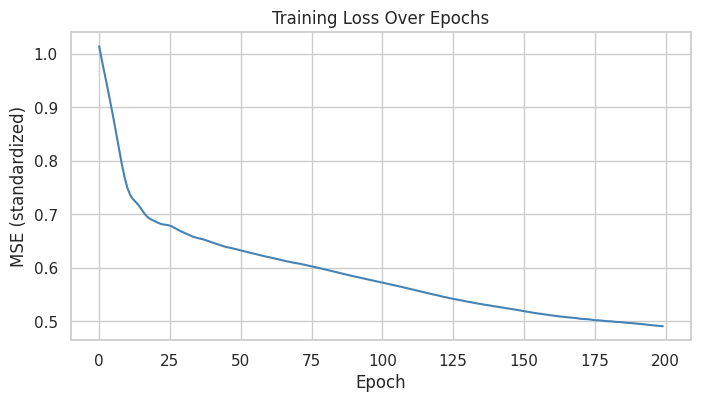

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(losses, color='steelblue')
ax.set_title('Training Loss Over Epochs')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE (standardized)')
plt.show()

## Evaluating the Network

- We predict on the test set, then un-standardize the predictions back to annualized-percent volatility.

- `torch.no_grad()` turns off gradient tracking during evaluation, which saves computation.

In [ ]:
from sklearn.metrics import r2_score

model.eval()
with torch.no_grad():
    pred_s = model(X_te_s).numpy().ravel()

# Convert predictions back to the original (annualized %) scale
nn_pred = pred_s * y_std + y_mean
nn_r2 = r2_score(y_te.ravel(), nn_pred)
print(f"Neural network volatility test R2: {nn_r2:.4f}")

Neural network volatility test R2: 0.1285


### Comparing the Neural Net to the Random Forest

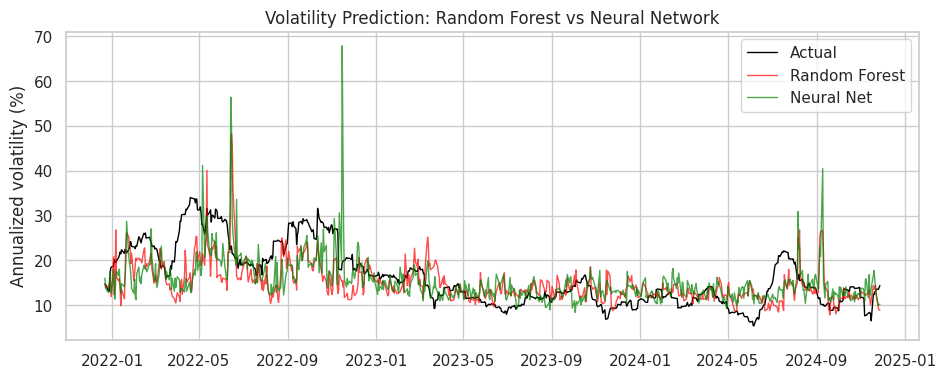

In [ ]:
rf_pred = rf_vol.predict(X_test)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(test.index, y_te.ravel(), label='Actual', color='black', linewidth=1)
ax.plot(test.index, rf_pred, label='Random Forest', color='red', linewidth=1, alpha=0.7)
ax.plot(test.index, nn_pred, label='Neural Net', color='green', linewidth=1, alpha=0.7)
ax.set_title('Volatility Prediction: Random Forest vs Neural Network')
ax.set_ylabel('Annualized volatility (%)')
ax.legend()
plt.show()

- On this tabular problem the neural net is not clearly better than the random forest.

- For tabular econ/finance data, tree ensembles are usually the practical default. Deep learning's advantage appears with unstructured data (text, images) and far larger datasets.

## When to Use Deep Learning

- Deep learning is rarely needed for a few hundred or a few thousand rows of tabular data. Gradient boosting is simpler and usually as good or better.

- It is useful when working with:
  - Text (central-bank statements, news, filings), using modern language models.
  - Images (satellite data, scanned documents).
  - Sequences where order and long-range structure matter.
  - Very large datasets, where flexible models have an advantage.

- These applications are built from the same components covered here: tensors, autograd, and the training loop.

## In-Class Exercise

**20-1. Tensors and Autograd:**
- Create a tensor `x = torch.tensor(2.0, requires_grad=True)`.
- Compute `y = x**3` and use `.backward()` to find `dy/dx` at x = 2. Confirm it equals 12 (since the derivative of x^3 is 3x^2).

**20-2. Build a Network:**
- Define a new `nn.Module` subclass with a single hidden layer of 32 units and a ReLU activation, mapping `len(feature_cols)` inputs to 1 output.
- Instantiate it and print the model.

**20-3. Train It:**
- Train your network from 20-2 on the standardized volatility data (`X_tr_s`, `y_tr_s`) for 150 epochs with the Adam optimizer and MSE loss.
- Store the per-epoch loss in a list and print the first and last values.

**20-4. Evaluate and Plot:**
- Plot the training-loss curve from 20-3.
- Then un-standardize the predictions and compute the test-set R-squared. How does it compare to the random forest?